# Khám phá dữ liệu LIDC-IDRI từng bước (Step-by-step Exploration)

Notebook này được tạo ra để khám phá dữ liệu từ ngoài vào trong, thông qua từng bước tương tác.

In [ ]:
# Bước 1: Kết nối với Google Drive (chỉ chạy trên Google Colab)
from google.colab import drive
drive.mount('/content/drive')
print('✅ Đã kết nối Google Drive thành công!')

Mounted at /content/drive
✅ Đã kết nối Google Drive thành công!


In [ ]:
# Bước 2: Khám phá cấp độ cao nhất - Danh sách Bệnh nhân (Patients)
import requests

BASE_URL = "https://services.cancerimagingarchive.net/nbia-api/services/v1"
endpoint = f"{BASE_URL}/getPatient"
params = {"Collection": "LIDC-IDRI", "format": "json"}

response = requests.get(endpoint, params=params)
patients = response.json()

print(f"✅ Đã tìm thấy tổng cộng {len(patients)} bệnh nhân!")
for i in range(len(patients)):
    print(f"{i+1}. Mã bệnh nhân: {patients[i]['PatientId']}")


✅ Đã tìm thấy tổng cộng 1010 bệnh nhân!
1. Mã bệnh nhân: LIDC-IDRI-0001
2. Mã bệnh nhân: LIDC-IDRI-0002
3. Mã bệnh nhân: LIDC-IDRI-0003
4. Mã bệnh nhân: LIDC-IDRI-0004
5. Mã bệnh nhân: LIDC-IDRI-0005
6. Mã bệnh nhân: LIDC-IDRI-0006
7. Mã bệnh nhân: LIDC-IDRI-0007
8. Mã bệnh nhân: LIDC-IDRI-0008
9. Mã bệnh nhân: LIDC-IDRI-0009
10. Mã bệnh nhân: LIDC-IDRI-0010
11. Mã bệnh nhân: LIDC-IDRI-0011
12. Mã bệnh nhân: LIDC-IDRI-0012
13. Mã bệnh nhân: LIDC-IDRI-0013
14. Mã bệnh nhân: LIDC-IDRI-0014
15. Mã bệnh nhân: LIDC-IDRI-0015
16. Mã bệnh nhân: LIDC-IDRI-0016
17. Mã bệnh nhân: LIDC-IDRI-0017
18. Mã bệnh nhân: LIDC-IDRI-0018
19. Mã bệnh nhân: LIDC-IDRI-0019
20. Mã bệnh nhân: LIDC-IDRI-0020
21. Mã bệnh nhân: LIDC-IDRI-0021
22. Mã bệnh nhân: LIDC-IDRI-0022
23. Mã bệnh nhân: LIDC-IDRI-0023
24. Mã bệnh nhân: LIDC-IDRI-0024
25. Mã bệnh nhân: LIDC-IDRI-0025
26. Mã bệnh nhân: LIDC-IDRI-0026
27. Mã bệnh nhân: LIDC-IDRI-0027
28. Mã bệnh nhân: LIDC-IDRI-0028
29. Mã bệnh nhân: LIDC-IDRI-0029
30. Mã bệnh 

In [ ]:
import json

file_path = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/Dataset_Preview/docs/patients.json"

with open(file_path, 'w', encoding='utf-8') as f:
  json.dump(patients, f, indent=4, ensure_ascii=False)


In [ ]:
# Bước 3: Khoan xuống cấp độ 2 - Xem các Lần chụp (Study) của 1 Bệnh nhân
patient_id = patients[1009]['PatientId']

endpoint_study = f"{BASE_URL}/getPatientStudy"
params_study = {"Collection": "LIDC-IDRI", "PatientID": patient_id, "format": "json"}

response_study = requests.get(endpoint_study, params=params_study)
studies = response_study.json()

print(f"✅ Bệnh nhân {patient_id} có {len(studies)} lần chụp (Study).")
for idx, study in enumerate(studies):
    study_uid = study['StudyInstanceUID']
    print(f"Lần chụp thứ {idx}: Mã số Study = {study_uid[-15:]}...")


✅ Bệnh nhân LIDC-IDRI-1008 có 1 lần chụp (Study).
Lần chụp thứ 0: Mã số Study = 481435949410827...


In [ ]:
import json

file_path = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/Dataset_Preview/docs/studies.json"

with open(file_path, 'w', encoding='utf-8') as f:
  json.dump(studies, f, indent=4, ensure_ascii=False)


In [ ]:
# Bước 4: Khảo sát Thống kê - Bệnh nhân chụp bao nhiêu lần?
import collections

# Không truyền PatientID vào nữa, ta yêu cầu TCIA gửi TẤT CẢ các lần chụp của toàn bộ LIDC-IDRI
endpoint_all_studies = f"{BASE_URL}/getPatientStudy"
params_all_studies = {"Collection": "LIDC-IDRI", "format": "json"}

print("Đang lấy dữ liệu toàn bộ các lần chụp (sẽ hơi lâu một chút)...")
response_all = requests.get(endpoint_all_studies, params=params_all_studies)
all_studies = response_all.json()

print(f"✅ Đã lấy được tổng cộng {len(all_studies)} lần chụp từ 1,010 bệnh nhân.")

# Lập bảng thống kê xem mỗi bệnh nhân chụp bao nhiêu lần
patient_study_counts = collections.defaultdict(int)
for study in all_studies:
    patient_id = study.get('PatientID', study.get('PatientId', 'Unknown'))
    patient_study_counts[patient_id] += 1

# Gom nhóm lại (bao nhiêu người chụp 1 lần, bao nhiêu người chụp 2 lần...)
from collections import Counter
summary = Counter(patient_study_counts.values())

print("\n📊 BẢNG THỐNG KÊ SỐ LẦN CHỤP (STUDY):")
for num_studies, num_patients in sorted(summary.items()):
    print(f"- Số người có đúng {num_studies} lần chụp: {num_patients} bệnh nhân")


Đang lấy dữ liệu toàn bộ các lần chụp (sẽ hơi lâu một chút)...
✅ Đã lấy được tổng cộng 1308 lần chụp từ 1,010 bệnh nhân.

📊 BẢNG THỐNG KÊ SỐ LẦN CHỤP (STUDY):
- Số người có đúng 1 lần chụp: 714 bệnh nhân
- Số người có đúng 2 lần chụp: 294 bệnh nhân
- Số người có đúng 3 lần chụp: 2 bệnh nhân


In [ ]:
# Bước 5: Lấy thông tin chi tiết (Series) bên trong các Lần chụp của 1 bệnh nhân

# Lấy lại mã số bệnh nhân đầu tiên
patient_id = patients[50]['PatientId']
print(f"🔍 Đang soi chi tiết hồ sơ bệnh nhân: {patient_id}\n")

# Hàm hỗ trợ gọi API cho gọn
def get_series_for_study(study_uid):
    endpoint = f"{BASE_URL}/getSeries"
    params = {"StudyInstanceUID": study_uid, "format": "json"}
    response = requests.get(endpoint, params=params)
    return response.json()

# Duyệt qua từng lần chụp (studies) đã tìm được ở Cell 3
for idx, study in enumerate(studies, 1):
    study_uid = study['StudyInstanceUID']
    study_date = study.get('StudyDate', 'Không rõ ngày')

    print(f"==== LẦN CHỤP THỨ {idx} (Ngày: {study_date}) ====")

    # Lấy chi tiết các chuỗi ảnh (Series) trong lần chụp này
    series_list = get_series_for_study(study_uid)
    print(f"Bác sĩ đã thực hiện {len(series_list)} loại dữ liệu (Series):")

    for s_idx, series in enumerate(series_list, 1):
        modality = series.get('Modality', 'Unknown')
        img_count = series.get('ImageCount', 0)
        desc = series.get('SeriesDescription', 'Không có mô tả')
        size_mb = float(series.get('FileSize', 0)) / (1024 * 1024)

        print(f"  {s_idx}. Chụp {modality} | Số ảnh: {img_count:>3} | Dung lượng: {size_mb:>5.1f} MB | Mô tả: {desc}")
    print("\n")


🔍 Đang soi chi tiết hồ sơ bệnh nhân: LIDC-IDRI-0051

==== LẦN CHỤP THỨ 1 (Ngày: 2000-01-01 00:00:00.0) ====
Bác sĩ đã thực hiện 23 loại dữ liệu (Series):
  1. Chụp CT | Số ảnh: 115 | Dung lượng:  57.7 MB | Mô tả: Không có mô tả
  2. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 2 - Annotation 15682
  3. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 5 - Annotation 80966
  4. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 1 - Annotation 80972
  5. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 2 - Annotation 80969
  6. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 1 - Annotation 3
  7. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 2 - Annotation 6
  8. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB | Mô tả: Segmentation of Nodule 4 - Annotation 80973
  9. Chụp SEG | Số ảnh:   1 | Dung lượng:   0.1 MB |

In [ ]:
import json

file_path = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/Dataset_Preview/docs/Series.json"

with open(file_path, 'w', encoding='utf-8') as f:
  json.dump(series, f, indent=4, ensure_ascii=False)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 24.3 MB/s eta 0:00:00
Đang tải cục dữ liệu CT (khoảng 70MB), vui lòng chờ...
Đang giải nén các file .dcm...
✅ Đã tải và giải nén xong tại thư mục: /content/lidc_demo/dicom

Đang mở thử file: 00000089.dcm
--- THÔNG TIN TRONG NGĂN SỐ 1 (METADATA) ---
Tên bệnh nhân: 
Phương thức chụp: CT
Máy chụp hãng: GE MEDICAL SYSTEMS
Tọa độ 3D của lát cắt này: [-166.000000, -171.699997, -235.000000]

--- THÔNG TIN TRONG NGĂN SỐ 2 (HÌNH ẢNH) ---


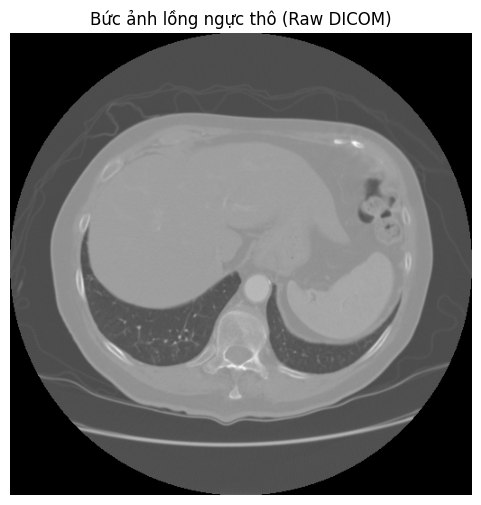

In [ ]:
# Bước 6: Tải dữ liệu thật về máy và "Bẻ khóa" file DICOM đầu tiên
!pip install pydicom -q
import os, zipfile, io
import pydicom
import matplotlib.pyplot as plt

# Lấy ID của chuỗi ảnh CT từ lần chụp của bệnh nhân LIDC-IDRI-0001 (Tôi đã tra sẵn cho bạn)
ct_series_uid = "1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636438705059720603192"

# Gọi máy chủ đóng gói toàn bộ ảnh CT này thành 1 file ZIP và gửi về
endpoint_download = f"{BASE_URL}/getImage"
params_download = {"SeriesInstanceUID": ct_series_uid}

print("Đang tải cục dữ liệu CT (khoảng 70MB), vui lòng chờ...")
response_zip = requests.get(endpoint_download, params=params_download)

# Giải nén cái cục ZIP vừa tải về vào thư mục /content/lidc_demo
extract_path = "/content/lidc_demo/dicom"
os.makedirs(extract_path, exist_ok=True)

print("Đang giải nén các file .dcm...")
with zipfile.ZipFile(io.BytesIO(response_zip.content)) as zip_ref:
    zip_ref.extractall(extract_path)

print(f"✅ Đã tải và giải nén xong tại thư mục: {extract_path}")

# --- BẺ KHÓA VÀ XEM FILE DICOM ĐẦU TIÊN ---
# Tìm tất cả file .dcm trong thư mục vừa giải nén (nhờ thư viện pathlib)
from pathlib import Path
dcm_files = list(Path(extract_path).rglob("*.dcm"))
first_file = dcm_files[0]

print(f"\nĐang mở thử file: {first_file.name}")

# Dùng chìa khóa pydicom mở ngăn thứ 1 (Siêu dữ liệu - Metadata)
dicom_data = pydicom.dcmread(first_file)
print("--- THÔNG TIN TRONG NGĂN SỐ 1 (METADATA) ---")
print(f"Tên bệnh nhân: {dicom_data.PatientName}")
print(f"Phương thức chụp: {dicom_data.Modality}")
print(f"Máy chụp hãng: {dicom_data.Manufacturer}")
print(f"Tọa độ 3D của lát cắt này: {dicom_data.ImagePositionPatient}")

# Dùng matplotlib để vẽ ngăn thứ 2 (Ma trận Pixel Data)
print("\n--- THÔNG TIN TRONG NGĂN SỐ 2 (HÌNH ẢNH) ---")
plt.figure(figsize=(6, 6))
plt.imshow(dicom_data.pixel_array, cmap="gray")
plt.title("Bức ảnh lồng ngực thô (Raw DICOM)")
plt.axis("off")
plt.show()


In [ ]:
# Bước 7: Khôi phục không gian 3D (Xếp Rubik)
import numpy as np

# 1. Đọc TOÀN BỘ 133 file vào một danh sách
print("Đang đọc tất cả các lát cắt...")
slices = [pydicom.dcmread(s) for s in dcm_files]

# In thử toạ độ Z của 3 file đầu tiên lúc chưa sắp xếp (sẽ thấy nó lộn xộn)
print("Tọa độ Z lúc chưa sắp xếp:")
for i in range(3):
    print(f"File {dcm_files[i].name} nằm ở độ cao: {slices[i].ImagePositionPatient[2]} mm")

# 2. Thuật toán sắp xếp (Sorting) dựa vào trục Z
# Trục Z chính là phần tử số 2 trong bộ tọa độ [X, Y, Z] của trường ImagePositionPatient
slices.sort(key=lambda x: float(x.ImagePositionPatient[2]), reverse=True)

print("\nTọa độ Z sau khi đã sắp xếp (Đã chuẩn không gian 3D):")
for i in range(3):
    print(f"Lát cắt thứ {i+1} nằm ở độ cao: {slices[i].ImagePositionPatient[2]} mm")

# 3. Ghép 133 lát cắt 2D lại thành 1 Khối Rubik 3D hoàn chỉnh
print("\nĐang ghép các lát cắt lại thành khối 3D...")

# Xếp chồng các ma trận pixel lên nhau
volume_3d = np.stack([s.pixel_array for s in slices])

print(f"✅ Đã tạo xong khối lượng lồng ngực 3D!")
print(f"Kích thước của khối 3D là: {volume_3d.shape} (Số lát cắt, Chiều cao, Chiều rộng)")


Đang đọc tất cả các lát cắt...
Tọa độ Z lúc chưa sắp xếp:
File 00000089.dcm nằm ở độ cao: -235.000000 mm
File 00000017.dcm nằm ở độ cao: -210.000000 mm
File 00000127.dcm nằm ở độ cao: -332.500000 mm

Tọa độ Z sau khi đã sắp xếp (Đã chuẩn không gian 3D):
Lát cắt thứ 1 nằm ở độ cao: -10.000000 mm
Lát cắt thứ 2 nằm ở độ cao: -12.500000 mm
Lát cắt thứ 3 nằm ở độ cao: -15.000000 mm

Đang ghép các lát cắt lại thành khối 3D...
✅ Đã tạo xong khối lượng lồng ngực 3D!
Kích thước của khối 3D là: (133, 512, 512) (Số lát cắt, Chiều cao, Chiều rộng)


In [ ]:
# Bước 8: Khảo sát diện rộng - Có bao nhiêu bệnh nhân thực sự có khối u trong toàn bộ tập dữ liệu?
import requests

print("Đang truy vấn máy chủ TCIA để quét toàn bộ 1,010 bệnh nhân (sẽ mất khoảng 10-20 giây)...")

# BÍ QUYẾT: Thay vì tải từng người, ta yêu cầu TCIA trả về TẤT CẢ các hồ sơ có nhãn 'SEG' trên toàn hệ thống
endpoint_seg = f"{BASE_URL}/getSeries"
params_seg = {"Collection": "LIDC-IDRI", "Modality": "SEG", "format": "json"}
response_seg = requests.get(endpoint_seg, params=params_seg)
all_seg_series = response_seg.json()

# Lọc ra danh sách các bệnh nhân (loại bỏ trùng lặp bằng cấu trúc Set)
cancer_patients = set()
for s in all_seg_series:
    p_id = s.get('PatientID', s.get('PatientId'))
    cancer_patients.add(p_id)

total_patients = 1010
cancer_count = len(cancer_patients)
clean_count = total_patients - cancer_count

print("\n📊 BÁO CÁO THỐNG KÊ TỔNG QUAN LIDC-IDRI:")
print("-" * 50)
print(f"Tổng số bệnh nhân tham gia chụp: {total_patients} người")
print(f"😷 Bệnh nhân CÓ khối u (có file SEG): {cancer_count} người ({cancer_count/total_patients*100:.1f}%)")
print(f"💚 Bệnh nhân KHỎE MẠNH (không có SEG): {clean_count} người ({clean_count/total_patients*100:.1f}%)")
print("-" * 50)
print("💡 KẾT LUẬN CHO AI: Khi tải dữ liệu để train MambaVision, bạn BẮT BUỘC phải dùng danh sách này để LỌC BỎ 135 người khỏe mạnh ra, tránh rác dữ liệu!")

# Cập nhật lại biến has_tumor cho bệnh nhân hiện tại (Để Cell 9 biết đường tải)
has_tumor = patient_id in cancer_patients


Đang truy vấn máy chủ TCIA để quét toàn bộ 1,010 bệnh nhân (sẽ mất khoảng 10-20 giây)...

📊 BÁO CÁO THỐNG KÊ TỔNG QUAN LIDC-IDRI:
--------------------------------------------------
Tổng số bệnh nhân tham gia chụp: 1010 người
😷 Bệnh nhân CÓ khối u (có file SEG): 875 người (86.6%)
💚 Bệnh nhân KHỎE MẠNH (không có SEG): 135 người (13.4%)
--------------------------------------------------
💡 KẾT LUẬN CHO AI: Khi tải dữ liệu để train MambaVision, bạn BẮT BUỘC phải dùng danh sách này để LỌC BỎ 135 người khỏe mạnh ra, tránh rác dữ liệu!


In [ ]:
# Bước 9: Chọn Bệnh nhân mục tiêu để tải dữ liệu và phân tích
# BẠN CÓ THỂ ĐỔI MÃ SỐ BỆNH NHÂN Ở ĐÂY TÙY Ý (Ví dụ: LIDC-IDRI-1008, LIDC-IDRI-0234...)
patient_id = "LIDC-IDRI-0001"

print(f"Đang kéo hồ sơ của bệnh nhân {patient_id} từ máy chủ...")

# Lấy danh sách lần chụp
endpoint_study = f"{BASE_URL}/getPatientStudy"
studies = requests.get(endpoint_study, params={"Collection": "LIDC-IDRI", "PatientID": patient_id}).json()

if not studies:
    print(f"❌ Không tìm thấy hồ sơ của bệnh nhân {patient_id}!")
    has_tumor = False
    series_list = []
else:
    # Lấy danh sách chuỗi ảnh (Series) của lần chụp cuối cùng
    study_uid = studies[-1]['StudyInstanceUID']
    series_list = requests.get(f"{BASE_URL}/getSeries", params={"StudyInstanceUID": study_uid}).json()

    # Kiểm tra xem có khối u không
    has_tumor = any(s.get('Modality') == 'SEG' for s in series_list)

    print("-" * 40)
    if has_tumor:
        print(f"✅ Bệnh nhân {patient_id} CÓ khối u. Hệ thống đã chốt danh sách Series và sẵn sàng tải xuống!")
    else:
        print(f"🛑 Bệnh nhân {patient_id} KHỎE MẠNH (Không có mặt nạ SEG). Hãy sửa code đổi sang ID khác!")


Đang kéo hồ sơ của bệnh nhân LIDC-IDRI-0001 từ máy chủ...
----------------------------------------
✅ Bệnh nhân LIDC-IDRI-0001 CÓ khối u. Hệ thống đã chốt danh sách Series và sẵn sàng tải xuống!


In [ ]:
# Bước 10: Chỉ tải dữ liệu NẾU bệnh nhân có khối u (Tối ưu hóa băng thông)
import os, zipfile, io, shutil
import requests
from google.colab import files

if has_tumor:
    print(f"Bệnh nhân {patient_id} CÓ khối u. Bắt đầu tiến hành tải trọn bộ hồ sơ...")

    patient_folder = f"/content/patient_{patient_id}_full"
    os.makedirs(patient_folder, exist_ok=True)

    for series in series_list:
        modality = series['Modality']
        if modality in ['CT', 'SEG']:
            series_uid = series['SeriesInstanceUID']
            print(f"Đang tải {modality} (Series UID: {series_uid[-10:]}...) ")

            endpoint_dl = f"{BASE_URL}/getImage"
            response_dl = requests.get(endpoint_dl, params={"SeriesInstanceUID": series_uid})

            series_folder = os.path.join(patient_folder, f"{modality}_{series_uid[-8:]}")
            os.makedirs(series_folder, exist_ok=True)

            with zipfile.ZipFile(io.BytesIO(response_dl.content)) as zip_ref:
                zip_ref.extractall(series_folder)

    print("\n✅ Đã tải và gom xong dữ liệu!")

    zip_path = f"/content/{patient_id}_full"
    shutil.make_archive(zip_path, 'zip', patient_folder)

    files.download(f"{zip_path}.zip")
    print(f"🎉 Đang tự động đẩy file '{patient_id}_full.zip' về máy tính của bạn!")
else:
    print(f"🛑 Bệnh nhân {patient_id} KHÔNG CÓ khối u lớn. Bỏ qua không tải để tiết kiệm bộ nhớ!")


Bệnh nhân LIDC-IDRI-0001 CÓ khối u. Bắt đầu tiến hành tải trọn bộ hồ sơ...
Đang tải CT (Series UID: 9720603192...) 
Đang tải SEG (Series UID: 067.990548...) 
Đang tải SEG (Series UID: 071.471973...) 
Đang tải SEG (Series UID: 075.626419...) 
Đang tải SEG (Series UID: 079.860324...) 

✅ Đã tải và gom xong dữ liệu!


KeyboardInterrupt: 

Đang giải phẫu file SEG để tìm tọa độ khối u...
🔥 Đã tìm thấy khối u này trải dài qua 9 lát cắt liên tiếp!
Đang tải 133 ảnh CT để bắt cặp tọa độ Z...


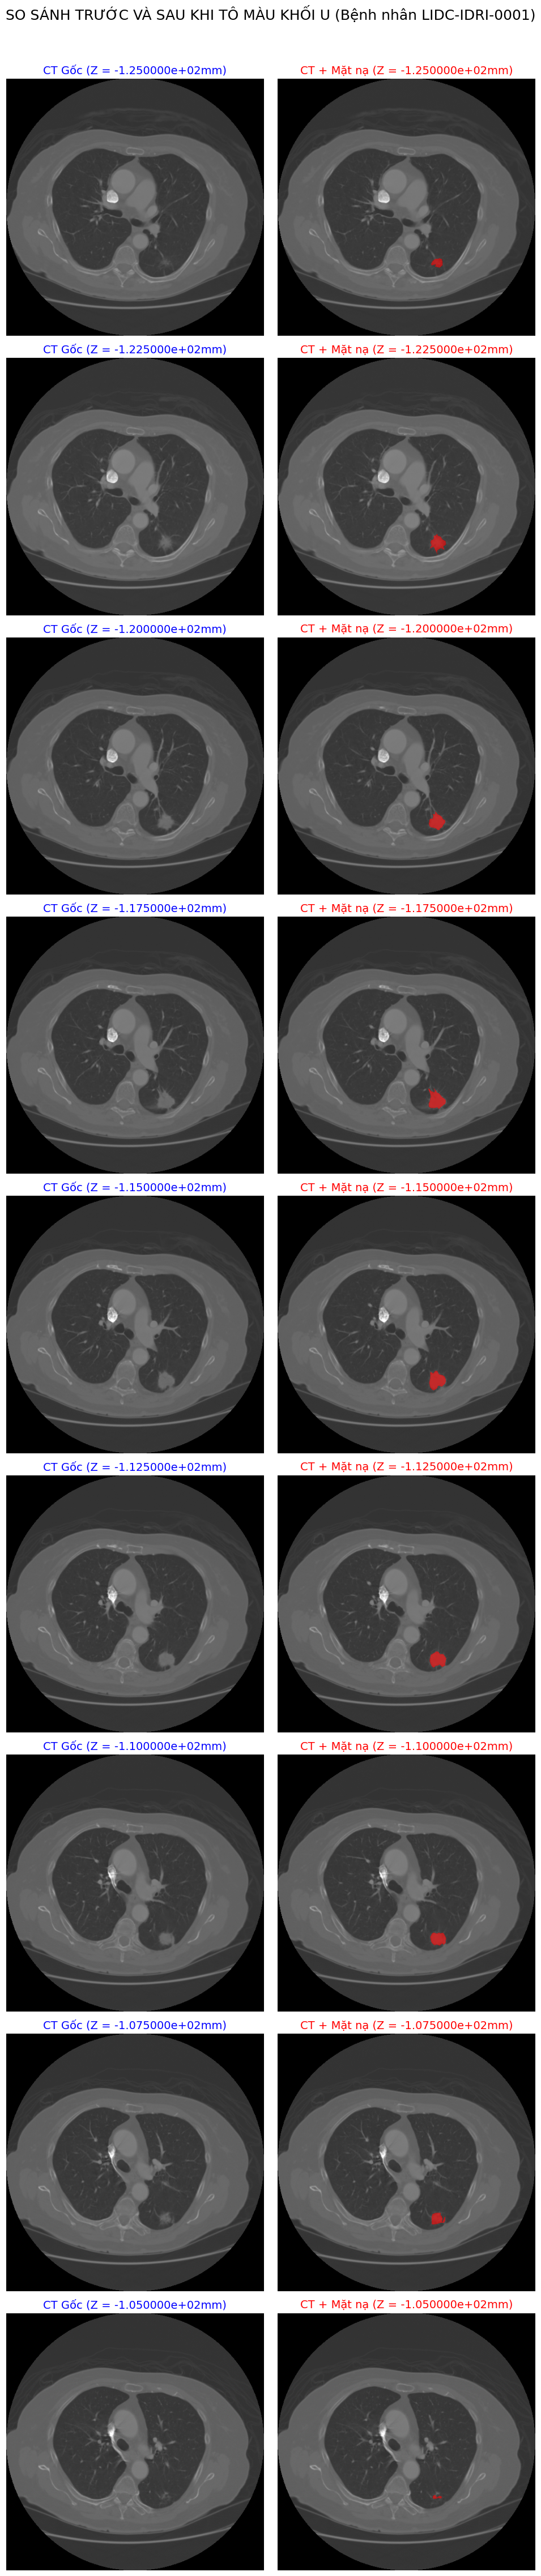

In [ ]:
# Bước 11: Tự tay dùng Python tìm và So sánh ảnh CT gốc vs Ảnh có Khối u
import pydicom
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

patient_folder = f"/content/patient_{patient_id}_full"

print("Đang giải phẫu file SEG để tìm tọa độ khối u...")
seg_files = list(Path(patient_folder).rglob("SEG*/*.dcm"))
seg_dcm = pydicom.dcmread(seg_files[0])
mask_3d = seg_dcm.pixel_array

target_frames = []
for i in range(mask_3d.shape[0]):
    if np.sum(mask_3d[i]) > 0:
        target_frames.append(i)

if not target_frames:
    print("Không tìm thấy vết vẽ nào trong file này.")
else:
    print(f"🔥 Đã tìm thấy khối u này trải dài qua {len(target_frames)} lát cắt liên tiếp!")
    print("Đang tải 133 ảnh CT để bắt cặp tọa độ Z...")

    ct_files = list(Path(patient_folder).rglob("CT*/*.dcm"))
    ct_slices = [pydicom.dcmread(f) for f in ct_files]

    # TẠO BẢNG VẼ: Nhiều hàng x 2 Cột (Trái: CT gốc | Phải: CT + SEG)
    fig, axes = plt.subplots(len(target_frames), 2, figsize=(10, 5 * len(target_frames)))

    # Ép kiểu ma trận axes về 2 chiều để tránh lỗi khi chỉ có 1 lát cắt
    if len(target_frames) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, frame_idx in enumerate(target_frames):
        mask_z = seg_dcm.PerFrameFunctionalGroupsSequence[frame_idx].PlanePositionSequence[0].ImagePositionPatient[2]

        target_ct = None
        for s in ct_slices:
            if abs(float(s.ImagePositionPatient[2]) - float(mask_z)) < 0.1:
                target_ct = s
                break

        if target_ct:
            # --- CỘT TRÁI (0): CHỈ VẼ CT GỐC ---
            axes[idx, 0].imshow(target_ct.pixel_array, cmap='gray')
            axes[idx, 0].set_title(f"CT Gốc (Z = {mask_z}mm)", fontsize=14, color='blue')
            axes[idx, 0].axis('off')

            # --- CỘT PHẢI (1): VẼ CT + MẶT NẠ ---
            axes[idx, 1].imshow(target_ct.pixel_array, cmap='gray')
            mask_layer = np.ma.masked_where(mask_3d[frame_idx] == 0, mask_3d[frame_idx])
            axes[idx, 1].imshow(mask_layer, cmap='hsv', alpha=0.6)
            axes[idx, 1].set_title(f"CT + Mặt nạ (Z = {mask_z}mm)", fontsize=14, color='red')
            axes[idx, 1].axis('off')

    plt.suptitle(f"SO SÁNH TRƯỚC VÀ SAU KHI TÔ MÀU KHỐI U (Bệnh nhân {patient_id})", fontsize=18, y=1.01)
    plt.tight_layout()
    plt.show()


In [ ]:
# Bước 12: Khảo sát chi tiết 100 bệnh nhân đầu tiên trong danh sách
import requests
import collections

print("Đang lấy dữ liệu toàn cục để tăng tốc độ phân tích...")
all_patients = requests.get(f"{BASE_URL}/getPatient", params={"Collection": "LIDC-IDRI", "format": "json"}).json()
first_100_ids = [p.get('PatientID', p.get('PatientId')) for p in all_patients[:100]]

all_studies = requests.get(f"{BASE_URL}/getPatientStudy", params={"Collection": "LIDC-IDRI", "format": "json"}).json()
all_series = requests.get(f"{BASE_URL}/getSeries", params={"Collection": "LIDC-IDRI", "format": "json"}).json()

# Gom nhóm Dữ liệu
patient_to_studies = collections.defaultdict(list)
for study in all_studies:
    pid = study.get('PatientID', study.get('PatientId'))
    patient_to_studies[pid].append(study['StudyInstanceUID'])

study_to_modalities = collections.defaultdict(set)
for series in all_series:
    study_to_modalities[series['StudyInstanceUID']].add(series['Modality'])

# Phân tích 100 người đầu tiên
cancer_count = 0
ct_count = 0
multiple_study_count = 0

print("\n🔍 KẾT QUẢ KHẢO SÁT 100 BỆNH NHÂN ĐẦU TIÊN:")
print("-" * 60)

for pid in first_100_ids:
    study_uids = patient_to_studies.get(pid, [])
    has_cancer = False
    has_ct = False

    patient_report = []
    for idx, suid in enumerate(study_uids, 1):
        mods = study_to_modalities.get(suid, set())
        patient_report.append(f"Lần {idx}: {list(mods)}")
        if 'SEG' in mods:
            has_cancer = True
        if 'CT' in mods:
            has_ct = True

    if has_cancer: cancer_count += 1
    if has_ct: ct_count += 1
    if len(study_uids) > 1: multiple_study_count += 1

    # In chi tiết từng người
    print(f"👤 {pid} | Có {len(study_uids)} lần chụp | Chi tiết: {' | '.join(patient_report)}")

print("\n📊 BẢNG TỔNG KẾT (TRÊN 100 NGƯỜI):")
print("-" * 40)
print(f"😷 Số người CÓ ung thư (chứa file SEG): {cancer_count}/100")
print(f"📸 Số người CÓ chụp CT: {ct_count}/100")
print(f"🏥 Số người đến viện chụp NHIỀU LẦN: {multiple_study_count}/100")


Đang lấy dữ liệu toàn cục để tăng tốc độ phân tích...

🔍 KẾT QUẢ KHẢO SÁT 100 BỆNH NHÂN ĐẦU TIÊN:
------------------------------------------------------------
👤 LIDC-IDRI-0001 | Có 2 lần chụp | Chi tiết: Lần 1: ['DX'] | Lần 2: ['CT', 'SR', 'SEG']
👤 LIDC-IDRI-0002 | Có 2 lần chụp | Chi tiết: Lần 1: ['DX'] | Lần 2: ['CT', 'SR', 'SEG']
👤 LIDC-IDRI-0003 | Có 2 lần chụp | Chi tiết: Lần 1: ['CT', 'SR', 'SEG'] | Lần 2: ['DX']
👤 LIDC-IDRI-0004 | Có 2 lần chụp | Chi tiết: Lần 1: ['CT', 'SR', 'SEG'] | Lần 2: ['CR']
👤 LIDC-IDRI-0005 | Có 2 lần chụp | Chi tiết: Lần 1: ['CT', 'SR', 'SEG'] | Lần 2: ['DX']
👤 LIDC-IDRI-0006 | Có 2 lần chụp | Chi tiết: Lần 1: ['CT', 'SR', 'SEG'] | Lần 2: ['DX']
👤 LIDC-IDRI-0007 | Có 2 lần chụp | Chi tiết: Lần 1: ['DX'] | Lần 2: ['CT', 'SR', 'SEG']
👤 LIDC-IDRI-0008 | Có 2 lần chụp | Chi tiết: Lần 1: ['CT', 'SR', 'SEG'] | Lần 2: ['DX']
👤 LIDC-IDRI-0009 | Có 2 lần chụp | Chi tiết: Lần 1: ['DX'] | Lần 2: ['CT', 'SR', 'SEG']
👤 LIDC-IDRI-0010 | Có 2 lần chụp | Chi tiết: Lần 

In [ ]:
# Bước 13: Tải "Vét" những bệnh nhân khỏe mạnh đã bị bỏ sót ở Lô tải đầu tiên
import os, zipfile, io
import requests

# Lô tải đầu tiên của bạn là 100 người CÓ BỆNH.
# Ta cần tính xem để tìm đủ 100 người có bệnh, hệ thống đã quét qua bao nhiêu người trong danh sách tổng.
count_cancer = 0
reach_index = 0
for i, p in enumerate(all_patients):
    pid = p.get('PatientID', p.get('PatientId'))
    if pid in cancer_patients:
        count_cancer += 1
    if count_cancer == 100:
        reach_index = i
        break

# Lọc ra những người KHỎE MẠNH nằm từ vị trí đầu tiên (0) cho đến vị trí reach_index
missed_healthy_patients = []
for p in all_patients[:reach_index+1]:
    pid = p.get('PatientID', p.get('PatientId'))
    if pid not in cancer_patients:
        missed_healthy_patients.append(pid)

print(f"🔍 Để tìm được 100 người có bệnh, hệ thống đã quét qua {reach_index + 1} người đầu tiên.")
print(f"💊 Trong đó có {len(missed_healthy_patients)} người KHỎE MẠNH đã bị bỏ qua.")
print(f"🚀 Đang tiến hành tải vét {len(missed_healthy_patients)} người khỏe mạnh này...")

dataset_dir = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/DATASET"
os.makedirs(dataset_dir, exist_ok=True)

for i, pid in enumerate(missed_healthy_patients):
    print(f"\n[{i+1}/{len(missed_healthy_patients)}] Đang tải hồ sơ khỏe mạnh: {pid}")
    patient_path = os.path.join(dataset_dir, pid)
    if os.path.exists(patient_path) and len(os.listdir(patient_path)) > 0:
        print("  -> Đã tồn tại, bỏ qua.")
        continue

    os.makedirs(patient_path, exist_ok=True)

    study_uids = patient_to_studies.get(pid, [])
    for suid in study_uids:
        series_in_study = [s for s in all_series if s['StudyInstanceUID'] == suid]
        for series in series_in_study:
            modality = series['Modality']

            # Người khỏe mạnh thì KHÔNG có file SEG, nên ta chỉ tải hình CT gốc
            if modality == 'CT':
                series_uid = series['SeriesInstanceUID']
                print(f"  + Đang kéo {modality}...")
                try:
                    r_dl = requests.get(f"{BASE_URL}/getImage", params={"SeriesInstanceUID": series_uid})
                    series_folder = os.path.join(patient_path, f"{modality}_{series_uid[-8:]}")
                    os.makedirs(series_folder, exist_ok=True)
                    with zipfile.ZipFile(io.BytesIO(r_dl.content)) as z:
                        z.extractall(series_folder)
                except Exception as e:
                    print(f"  -> Lỗi mạng khi tải {modality}.")

print("\n🎉 ĐÃ TẢI VÉT THÀNH CÔNG! Bây giờ tập dữ liệu của bạn đã hoàn hảo không bị thủng lỗ nào.")


🔍 Để tìm được 100 người có bệnh, hệ thống đã quét qua 105 người đầu tiên.
💊 Trong đó có 5 người KHỎE MẠNH đã bị bỏ qua.
🚀 Đang tiến hành tải vét 5 người khỏe mạnh này...

[1/5] Đang tải hồ sơ khỏe mạnh: LIDC-IDRI-0028
  + Đang kéo CT...

[2/5] Đang tải hồ sơ khỏe mạnh: LIDC-IDRI-0032
  + Đang kéo CT...

[3/5] Đang tải hồ sơ khỏe mạnh: LIDC-IDRI-0062
  + Đang kéo CT...

[4/5] Đang tải hồ sơ khỏe mạnh: LIDC-IDRI-0071
  + Đang kéo CT...

[5/5] Đang tải hồ sơ khỏe mạnh: LIDC-IDRI-0100
  + Đang kéo CT...

🎉 ĐÃ TẢI VÉT THÀNH CÔNG! Bây giờ tập dữ liệu của bạn đã hoàn hảo không bị thủng lỗ nào.


In [ ]:
# Bước 14: Tải hàng loạt dữ liệu theo Giai đoạn (Phân lô tải)
import os, zipfile, io
import requests

# ĐIỀU CHỈNH KHOẢNG BỆNH NHÂN BẠN MUỐN TẢI TẠI ĐÂY
# (Ví dụ: Bạn đã tải 100 người đầu, giờ bạn muốn tải từ người số 100 đến 200)
start_index = 100
end_index = 300

# Đích đến trên Google Drive
dataset_dir = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/DATASET"
os.makedirs(dataset_dir, exist_ok=True)

print(f"🚀 Bắt đầu chiến dịch tải từ bệnh nhân số {start_index} đến {end_index}...")

# Lấy danh sách bệnh nhân theo đúng khoảng đã chỉ định
# LƯU Ý: Lần này ta gom TẤT CẢ (cả người có u lẫn người khỏe mạnh)
target_patients = []
for p in all_patients[start_index:end_index]:
    pid = p.get('PatientID', p.get('PatientId'))
    target_patients.append(pid)

# Bắt đầu vòng lặp tải
for i, pid in enumerate(target_patients):
    print(f"\n[{start_index + i}/{end_index}] Đang xử lý hồ sơ: {pid}")

    patient_path = os.path.join(dataset_dir, pid)
    if os.path.exists(patient_path) and len(os.listdir(patient_path)) > 0:
        print("  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.")
        continue

    os.makedirs(patient_path, exist_ok=True)

    study_uids = patient_to_studies.get(pid, [])
    for suid in study_uids:
        series_in_study = [s for s in all_series if s['StudyInstanceUID'] == suid]

        for series in series_in_study:
            modality = series['Modality']

            if modality in ['CT', 'SEG']:
                series_uid = series['SeriesInstanceUID']
                print(f"  + Đang kéo {modality} từ máy chủ...")

                try:
                    r_dl = requests.get(f"{BASE_URL}/getImage", params={"SeriesInstanceUID": series_uid})
                    series_folder = os.path.join(patient_path, f"{modality}_{series_uid[-8:]}")
                    os.makedirs(series_folder, exist_ok=True)

                    with zipfile.ZipFile(io.BytesIO(r_dl.content)) as z:
                        z.extractall(series_folder)
                except Exception as e:
                    print(f"  -> Lỗi mạng khi tải {modality}. Sẽ bỏ qua.")

print("\n🎉 HOÀN THÀNH LÔ TẢI HIỆN TẠI!")


🚀 Bắt đầu chiến dịch tải từ bệnh nhân số 100 đến 300...

[100/300] Đang xử lý hồ sơ: LIDC-IDRI-0109
  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.

[101/300] Đang xử lý hồ sơ: LIDC-IDRI-0110
  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.

[102/300] Đang xử lý hồ sơ: LIDC-IDRI-0111
  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.

[103/300] Đang xử lý hồ sơ: LIDC-IDRI-0112
  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.

[104/300] Đang xử lý hồ sơ: LIDC-IDRI-0113
  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.

[105/300] Đang xử lý hồ sơ: LIDC-IDRI-0114
  + Đang kéo CT từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...

[106/300] Đang xử lý hồ sơ: LIDC-IDRI-0116
  + Đang kéo CT từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy 

In [ ]:
# Bước 14: Tải hàng loạt dữ liệu theo Giai đoạn (Phân lô tải)
import os, zipfile, io
import requests

# ĐIỀU CHỈNH KHOẢNG BỆNH NHÂN BẠN MUỐN TẢI TẠI ĐÂY
# (Ví dụ: Bạn đã tải 100 người đầu, giờ bạn muốn tải từ người số 100 đến 200)
start_index = 300
end_index = 700

# Đích đến trên Google Drive
dataset_dir = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/DATASET"
os.makedirs(dataset_dir, exist_ok=True)

print(f"🚀 Bắt đầu chiến dịch tải từ bệnh nhân số {start_index} đến {end_index}...")

# Lấy danh sách bệnh nhân theo đúng khoảng đã chỉ định
# LƯU Ý: Lần này ta gom TẤT CẢ (cả người có u lẫn người khỏe mạnh)
target_patients = []
for p in all_patients[start_index:end_index]:
    pid = p.get('PatientID', p.get('PatientId'))
    target_patients.append(pid)

# Bắt đầu vòng lặp tải
for i, pid in enumerate(target_patients):
    print(f"\n[{start_index + i}/{end_index}] Đang xử lý hồ sơ: {pid}")

    patient_path = os.path.join(dataset_dir, pid)
    if os.path.exists(patient_path) and len(os.listdir(patient_path)) > 0:
        print("  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.")
        continue

    os.makedirs(patient_path, exist_ok=True)

    study_uids = patient_to_studies.get(pid, [])
    for suid in study_uids:
        series_in_study = [s for s in all_series if s['StudyInstanceUID'] == suid]

        for series in series_in_study:
            modality = series['Modality']

            if modality in ['CT', 'SEG']:
                series_uid = series['SeriesInstanceUID']
                print(f"  + Đang kéo {modality} từ máy chủ...")

                try:
                    r_dl = requests.get(f"{BASE_URL}/getImage", params={"SeriesInstanceUID": series_uid})
                    series_folder = os.path.join(patient_path, f"{modality}_{series_uid[-8:]}")
                    os.makedirs(series_folder, exist_ok=True)

                    with zipfile.ZipFile(io.BytesIO(r_dl.content)) as z:
                        z.extractall(series_folder)
                except Exception as e:
                    print(f"  -> Lỗi mạng khi tải {modality}. Sẽ bỏ qua.")

print("\n🎉 HOÀN THÀNH LÔ TẢI HIỆN TẠI!")


🚀 Bắt đầu chiến dịch tải từ bệnh nhân số 300 đến 700...

[300/700] Đang xử lý hồ sơ: LIDC-IDRI-0331
  + Đang kéo CT từ máy chủ...

[301/700] Đang xử lý hồ sơ: LIDC-IDRI-0332
  + Đang kéo CT từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo CT từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...

[302/700] Đang xử lý hồ sơ: LIDC-IDRI-0334
  + Đang kéo CT từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang kéo SEG từ máy chủ...
  + Đang k

In [ ]:
# Bước 14: Tải hàng loạt dữ liệu theo Giai đoạn (Phân lô tải)
import os, zipfile, io
import requests

# ĐIỀU CHỈNH KHOẢNG BỆNH NHÂN BẠN MUỐN TẢI TẠI ĐÂY
# (Ví dụ: Bạn đã tải 100 người đầu, giờ bạn muốn tải từ người số 100 đến 200)
start_index = 700
end_index = 1010

# Đích đến trên Google Drive
dataset_dir = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/DATASET"
os.makedirs(dataset_dir, exist_ok=True)

print(f"🚀 Bắt đầu chiến dịch tải từ bệnh nhân số {start_index} đến {end_index}...")

# Lấy danh sách bệnh nhân theo đúng khoảng đã chỉ định
# LƯU Ý: Lần này ta gom TẤT CẢ (cả người có u lẫn người khỏe mạnh)
target_patients = []
for p in all_patients[start_index:end_index]:
    pid = p.get('PatientID', p.get('PatientId'))
    target_patients.append(pid)

# Bắt đầu vòng lặp tải
for i, pid in enumerate(target_patients):
    print(f"\n[{start_index + i}/{end_index}] Đang xử lý hồ sơ: {pid}")

    patient_path = os.path.join(dataset_dir, pid)
    if os.path.exists(patient_path) and len(os.listdir(patient_path)) > 0:
        print("  -> Dữ liệu đã có sẵn trong Drive, bỏ qua để tải người tiếp theo.")
        continue

    os.makedirs(patient_path, exist_ok=True)

    study_uids = patient_to_studies.get(pid, [])
    for suid in study_uids:
        series_in_study = [s for s in all_series if s['StudyInstanceUID'] == suid]

        for series in series_in_study:
            modality = series['Modality']

            if modality in ['CT', 'SEG']:
                series_uid = series['SeriesInstanceUID']
                print(f"  + Đang kéo {modality} từ máy chủ...")

                try:
                    r_dl = requests.get(f"{BASE_URL}/getImage", params={"SeriesInstanceUID": series_uid})
                    series_folder = os.path.join(patient_path, f"{modality}_{series_uid[-8:]}")
                    os.makedirs(series_folder, exist_ok=True)

                    with zipfile.ZipFile(io.BytesIO(r_dl.content)) as z:
                        z.extractall(series_folder)
                except Exception as e:
                    print(f"  -> Lỗi mạng khi tải {modality}. Sẽ bỏ qua.")

print("\n🎉 HOÀN THÀNH LÔ TẢI HIỆN TẠI!")


In [13]:
# Bước 15: Kiểm toán dữ liệu (Data Audit) - Kiểm tra lỗi tải và thư mục rác
import os
import requests
from pathlib import Path
from tqdm.notebook import tqdm

dataset_dir = "/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_KH1_(2026-2027)/CT208E/SOURCES/DATASET"

print("Đang lấy danh sách thư mục từ Google Drive...")
all_items_in_drive = os.listdir(dataset_dir) if os.path.exists(dataset_dir) else []

print("Đang tải danh sách 1,010 ID gốc từ máy chủ TCIA...")
all_patients_api = requests.get(f"{BASE_URL}/getPatient", params={"Collection": "LIDC-IDRI", "format": "json"}).json()
valid_ids_from_api = set([p.get('PatientID', p.get('PatientId')) for p in all_patients_api])

print(f"\n🔍 KẾT QUẢ KIỂM TOÁN TỔNG QUAN:")
print("-" * 50)
print(f"- Tổng số mục (folders/files) tìm thấy trong Drive: {len(all_items_in_drive)}")
print(f"- Tổng số bệnh nhân chuẩn của TCIA: {len(valid_ids_from_api)}")

# Phân loại thư mục
valid_downloaded_patients = []
trash_or_extra_items = []

for item in all_items_in_drive:
    if item in valid_ids_from_api:
        valid_downloaded_patients.append(item)
    else:
        trash_or_extra_items.append(item)

print("\n🗑️ PHÂN TÍCH NHỮNG MỤC DƯ THỪA (TẠI SAO > 1010?):")
if len(trash_or_extra_items) == 0:
    print("Tuyệt vời! Không có thư mục rác nào.")
else:
    print(f"Phát hiện {len(trash_or_extra_items)} mục không phải là ID bệnh nhân chuẩn:")
    for t in trash_or_extra_items:
        print(f"  [Rác/File hệ thống] -> {t}")
    print("(Bạn hãy vào Drive xóa các mục này đi cho sạch bộ dữ liệu nhé!)")

print("\n🔎 KIỂM TRA ĐỘ TOÀN VẸN VỀ SỐ LƯỢNG:")
missing_patients = valid_ids_from_api - set(valid_downloaded_patients)
if len(missing_patients) > 0:
    print(f"⚠️ BÁO ĐỘNG: Bạn ĐANG TẢI THIẾU {len(missing_patients)} bệnh nhân so với gốc!")
else:
    print("✅ XUẤT SẮC: Bạn đã tải ĐỦ 100% (1,010/1,010 bệnh nhân) có mặt trên máy chủ TCIA!")

print("\n🛠️ KIỂM TRA LỖI BÊN TRONG THƯ MỤC (Thư mục rỗng/Tải lỗi):")
empty_folders = []

# Dùng tqdm để hiển thị thanh tiến trình cực kỳ đẹp mắt
for pid in tqdm(valid_downloaded_patients, desc="Đang quét tìm file .dcm"):
    path = os.path.join(dataset_dir, pid)
    dcm_count = len(list(Path(path).rglob("*.dcm")))
    if dcm_count == 0:
        empty_folders.append(pid)

if len(empty_folders) > 0:
    print(f"\n❌ Phát hiện {len(empty_folders)} thư mục RỖNG (Bị rớt mạng lúc tải). Bạn cần xóa các thư mục này và tải lại:")
    print(empty_folders)
else:
    print("\n✅ Tuyệt vời! Tất cả các thư mục đều chứa ảnh DICOM đầy đủ, không có thư mục nào rỗng.")


Đang lấy danh sách thư mục từ Google Drive...
Đang tải danh sách 1,010 ID gốc từ máy chủ TCIA...

🔍 KẾT QUẢ KIỂM TOÁN TỔNG QUAN:
--------------------------------------------------
- Tổng số mục (folders/files) tìm thấy trong Drive: 1010
- Tổng số bệnh nhân chuẩn của TCIA: 1010

🗑️ PHÂN TÍCH NHỮNG MỤC DƯ THỪA (TẠI SAO > 1010?):
Tuyệt vời! Không có thư mục rác nào.

🔎 KIỂM TRA ĐỘ TOÀN VẸN VỀ SỐ LƯỢNG:
✅ XUẤT SẮC: Bạn đã tải ĐỦ 100% (1,010/1,010 bệnh nhân) có mặt trên máy chủ TCIA!

🛠️ KIỂM TRA LỖI BÊN TRONG THƯ MỤC (Thư mục rỗng/Tải lỗi):


Đang quét tìm file .dcm:   0%|          | 0/1010 [00:00<?, ?it/s]


✅ Tuyệt vời! Tất cả các thư mục đều chứa ảnh DICOM đầy đủ, không có thư mục nào rỗng.
